**Import libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


**Load the Excel dataset**

In [ ]:
# Load the uploaded Excel file
file_path = "/content/ApexPlanet_DataAnalytics_Dataset.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

print("\nFirst five rows:")
display(df.head())

Dataset loaded successfully!
Number of rows and columns: (1000, 12)

First five rows:


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


**Check the data quality and date range**

In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-missing values:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nExact duplicate rows:")
print(df.duplicated().sum())

print("\nDuplicate Order IDs:")
print(df["Order_ID"].duplicated().sum())

# Convert dates for analysis
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], errors="coerce"
)

print("\nFirst order date:", df["Order_Date"].min())
print("Last order date:", df["Order_Date"].max())

print("\nSales summary:")
display(
    df[["Quantity", "Unit_Price", "Total_Sales"]].describe()
)

Column names:
['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Total_Sales']

Data types and non-missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       1000 non-null   object 
 1   Order_Date     1000 non-null   object 
 2   Customer_ID    1000 non-null   object 
 3   Customer_Name  1000 non-null   object 
 4   Age            980 non-null    float64
 5   Gender         1000 non-null   object 
 6   City           987 non-null    object 
 7   Product        1000 non-null   object 
 8   Category       1000 non-null   object 
 9   Quantity       1000 non-null   int64  
 10  Unit_Price     1000 non-null   float64
 11  Total_Sales    1000 non-null   float64
dtypes: float64(3), int64(1), object(8)
memory usage: 93.9+ KB

Missing values:


,Missing Values
Order_ID,0
Order_Date,0
Customer_ID,0
Customer_Name,0
Age,20
Gender,0
City,13
Product,0
Category,0
Quantity,0



Exact duplicate rows:
0

Duplicate Order IDs:
8

First order date: 2025-01-01 00:00:00
Last order date: 2026-01-01 00:00:00

Sales summary:


,Quantity,Unit_Price,Total_Sales
count,1000.000000,1000.000000,1000.000000
mean,5.435000,25486.783410,139399.439650
std,2.838632,14179.402361,114100.051546
min,1.000000,145.780000,437.340000
25%,3.000000,13895.722500,47066.632500
50%,5.000000,25398.740000,108594.025000
75%,8.000000,37512.382500,203722.882500
max,10.000000,49997.530000,493677.500000


**Calculate the five KPIs**

In [ ]:
# STEP 6: CORE KPI CALCULATIONS

# Make sure the order dates are in date format
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], errors="coerce"
)

# 1. Total Revenue
total_revenue = df["Total_Sales"].sum()

# 2. Total Unique Orders
total_orders = df["Order_ID"].nunique()

# 3. Average Order Value
average_order_value = (
    total_revenue / total_orders if total_orders > 0 else 0
)

# 4. Total Quantity Sold
total_quantity = df["Quantity"].sum()

# 5. Total Unique Customers
total_customers = df["Customer_ID"].nunique()

# Display KPIs
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Unique Orders",
        "Average Order Value",
        "Total Quantity Sold",
        "Total Unique Customers"
    ],
    "Value": [
        round(total_revenue, 2),
        total_orders,
        round(average_order_value, 2),
        total_quantity,
        total_customers
    ]
})

display(kpi_summary)

,KPI,Value
0,Total Revenue,1.393994e+08
1,Total Unique Orders,9.920000e+02
2,Average Order Value,1.405236e+05
3,Total Quantity Sold,5.435000e+03
4,Total Unique Customers,9.470000e+02


**Calculate monthly revenue and growth**

In [ ]:
# Group sales by month
monthly_sales = (
    df.dropna(subset=["Order_Date"])
      .set_index("Order_Date")["Total_Sales"]
      .resample("MS")
      .sum()
      .rename("Monthly_Revenue")
      .to_frame()
)

# Calculate month-over-month revenue growth
monthly_sales["Revenue_Growth_%"] = (
    monthly_sales["Monthly_Revenue"]
    .pct_change()
    .mul(100)
)

display(monthly_sales.round(2))

,Monthly_Revenue,Revenue_Growth_%
Order_Date,,
2025-01-01,10096190.73,NaN
2025-02-01,11511181.46,14.02
2025-03-01,13059899.94,13.45
2025-04-01,12222700.17,-6.41
2025-05-01,10984689.25,-10.13
2025-06-01,12912332.64,17.55
2025-07-01,11746226.80,-9.03
2025-08-01,9448471.22,-19.56
2025-09-01,9179896.29,-2.84


**Save the KPI results**

In [ ]:
# Save KPI results
kpi_summary.to_csv("task3_kpi_summary.csv", index=False)

# Save monthly revenue analysis
monthly_sales.to_csv("task3_monthly_sales.csv")

print("KPI summary saved successfully!")
print("Monthly sales report saved successfully!")

KPI summary saved successfully!
Monthly sales report saved successfully!


**Download the files**

In [ ]:
from google.colab import files

files.download("task3_kpi_summary.csv")
files.download("task3_monthly_sales.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Create my first business charts**

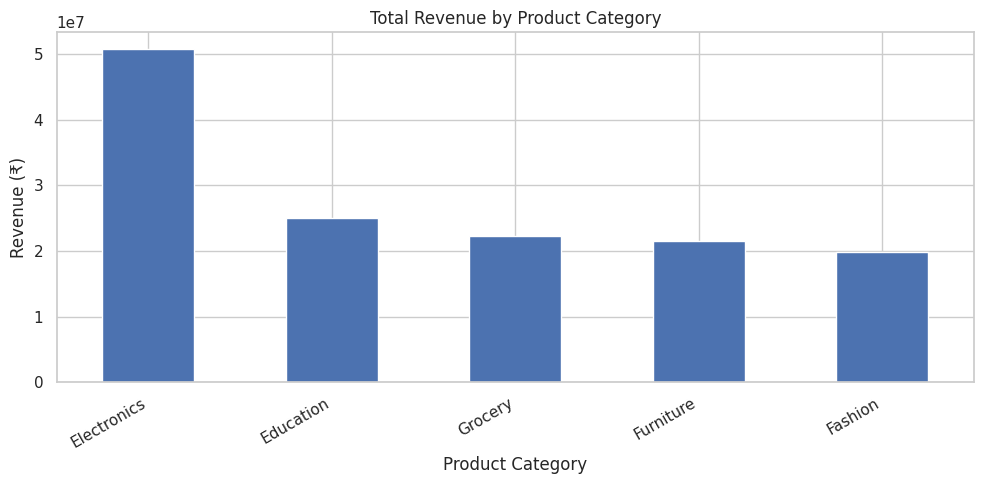

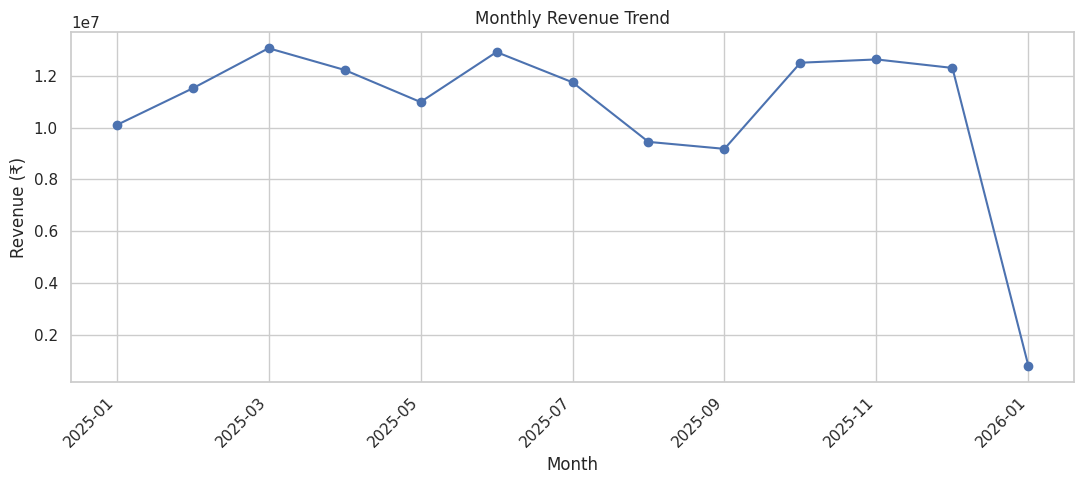

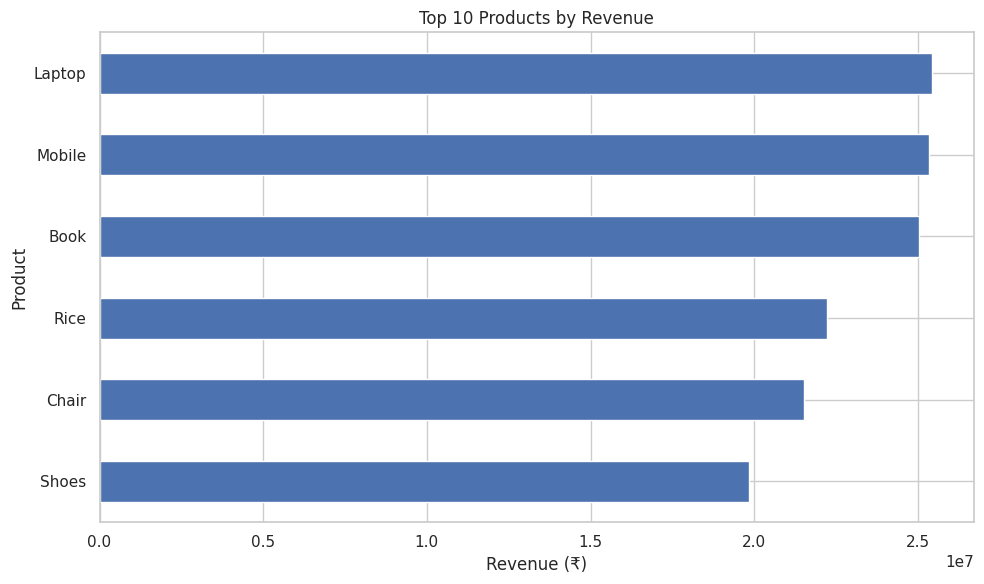

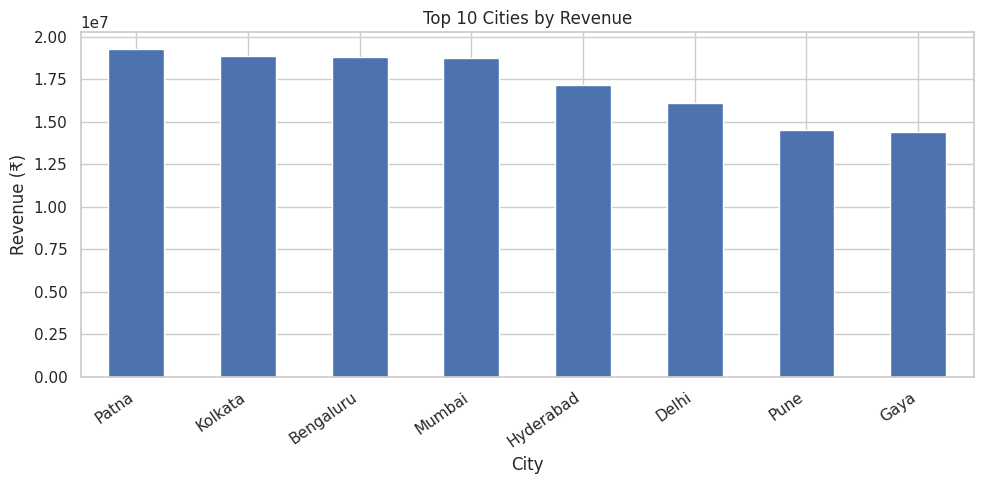

In [9]:

# SALES PERFORMANCE VISUALIZATIONS

# Set a clean chart style
sns.set_theme(style="whitegrid")

# 1. Revenue by Product Category
category_sales = (
    df.groupby("Category")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
category_sales.plot(kind="bar")
plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# 2. Monthly Revenue Trend
monthly_revenue = (
    df.dropna(subset=["Order_Date"])
    .groupby(df["Order_Date"].dt.to_period("M"))["Total_Sales"]
    .sum()
)

plt.figure(figsize=(11, 5))
monthly_revenue.index = monthly_revenue.index.astype(str)
monthly_revenue.plot(marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 3. Top 10 Products by Revenue
top_products = (
    df.groupby("Product")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
top_products.plot(kind="barh")
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (₹)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

# 4. Revenue by City
city_sales = (
    df.groupby("City")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))
city_sales.plot(kind="bar")
plt.title("Top 10 Cities by Revenue")
plt.xlabel("City")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

**Find the actual top-performing categories and products**

In [10]:

print("TOP PRODUCT CATEGORIES")
display(category_sales.reset_index(name="Total_Revenue")
        .sort_values("Total_Revenue", ascending=False)
        .round(2))

print("\nTOP 10 PRODUCTS")
display(top_products.reset_index(name="Total_Revenue")
        .sort_values("Total_Revenue", ascending=False)
        .round(2))

print("\nTOP 10 CITIES")
display(city_sales.reset_index(name="Total_Revenue")
        .round(2))


TOP PRODUCT CATEGORIES


,Category,Total_Revenue
0,Electronics,50778581.70
1,Education,25031689.40
2,Grocery,22231711.28
3,Furniture,21521561.48
4,Fashion,19835895.79



TOP 10 PRODUCTS


,Product,Total_Revenue
5,Laptop,25443008.51
4,Mobile,25335573.19
3,Book,25031689.40
2,Rice,22231711.28
1,Chair,21521561.48
0,Shoes,19835895.79



TOP 10 CITIES


,City,Total_Revenue
0,Patna,19285966.89
1,Kolkata,18884349.57
2,Bengaluru,18773574.32
3,Mumbai,18757050.17
4,Hyderabad,17166766.87
5,Delhi,16097079.00
6,Pune,14513175.90
7,Gaya,14380859.39


**Business insight - 1:** Electronics is the leading category, contributing approximately 36.4% of total revenue. Education ranks second. Together, these two categories generate around 54.4% of total revenue, indicating that they are important categories for the business.

**Business insight - 2:** Laptops and mobiles generate the highest revenue among the listed products. The business could investigate customer demand, pricing, and product availability for these products to identify opportunities for further growth.

**Business insight - 3:** Patna generates the highest revenue, followed by Kolkata and Bengaluru. The company could examine customer preferences and sales strategies in these cities to understand what contributes to their performance.